## Emmaus

# Distribution of predicted ratings (test set, mask models)

How many of the 290 test nodules each final model assigns to each rating, next to the true (median) ratings.

- **Single split:** models A and B, mean ± SD over seeds 1-3 (`runs/cls_no_fold_mask`)
- **Folds:** models A and B, mean ± SD over the 4 fold models (`runs/cls_mask`)
- **Folds ensembles:** the 4 fold models' probabilities averaged per nodule, as in `score_test_fold.py`.
  One combined model, so one count and no SD.

The predicted rating is the rating with the highest probability. Both approaches are tested on the same 290 nodules
(fold 0 = the single split's test set).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
SINGLE_DIR = PROJECT / "runs" / "cls_no_fold_mask"
FOLDS_DIR = PROJECT / "runs" / "cls_mask"
SEEDS = [1, 2, 3]
FOLDS = [1, 2, 3, 4]
RATINGS = [1, 2, 3, 4, 5]
P_COLS = [f"p{k}" for k in RATINGS]

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
assert set(test.index) == set(labels.loc[labels["fold"] == 0, "nodule_key"]), "fold 0 should be the single split's test set"
print(f"{len(test)} test nodules")

290 test nodules


## Count the predicted ratings of every run

In [2]:
def probs_of(run_dir):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(run_dir / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

def count(probs):
    """How many nodules get each rating 1-5 (the rating with the highest probability)."""
    predicted = probs.argmax(axis=1) + 1
    return np.array([(predicted == r).sum() for r in RATINGS])

# one count per run: rows = runs, columns = ratings 1-5
groups = {}
for kind, model in (("hard", "A"), ("soft", "B")):
    groups[f"Single split, model {model}"] = np.array([count(probs_of(SINGLE_DIR / f"{kind}_seed{s}")) for s in SEEDS])
    fold_probs = [probs_of(FOLDS_DIR / f"{kind}_fold{k}") for k in FOLDS]
    groups[f"Folds, model {model}"] = np.array([count(p) for p in fold_probs])
    groups[f"Folds ensemble, model {model}"] = count(np.mean(fold_probs, axis=0))[None, :]   # one combined model

true_counts = np.array([(test["hard"] == r).sum() for r in RATINGS])

## Table (mean ± SD)

SD is the sample standard deviation over the seeds or folds (the same as `summary.csv`).

In [3]:
ORDER = ["Single split, model A", "Single split, model B",
         "Folds, model A", "Folds, model B",
         "Folds ensemble, model A", "Folds ensemble, model B"]

rows = {"True (median rating)": [str(c) for c in true_counts]}
means, sds = {}, {}
for name in ORDER:
    runs = groups[name]
    means[name] = runs.mean(axis=0)
    if len(runs) > 1:
        sds[name] = runs.std(axis=0, ddof=1)
        rows[name] = [f"{m:.1f} ± {s:.1f}" for m, s in zip(means[name], sds[name])]
    else:
        sds[name] = None
        rows[name] = [f"{m:.0f}" for m in means[name]]

table = pd.DataFrame(rows, index=[f"Rating {r}" for r in RATINGS]).T
table

,Rating 1,Rating 2,Rating 3,Rating 4,Rating 5
True (median rating),37,46,136,44,27
"Single split, model A",36.7 ± 2.3,5.3 ± 9.2,187.7 ± 9.5,28.0 ± 4.4,32.3 ± 3.2
"Single split, model B",40.0 ± 2.0,3.7 ± 3.1,199.3 ± 6.8,6.3 ± 8.4,40.7 ± 5.1
"Folds, model A",37.2 ± 4.6,6.5 ± 5.4,187.5 ± 9.3,27.8 ± 5.4,31.0 ± 5.6
"Folds, model B",39.0 ± 1.4,4.0 ± 8.0,200.5 ± 13.9,6.5 ± 8.7,40.0 ± 7.1
"Folds ensemble, model A",39,3,190,27,31
"Folds ensemble, model B",38,0,208,4,40


## Bar charts

One chart per approach. Bars are the mean over the seeds or folds; error bars run from the lowest to the
highest run, so they can't go below 0. The ensembles have no error bars (one model).
Both charts use the same vertical scale, so they can be compared.

In [4]:
Y_MAX = 1.1 * max(true_counts.max(), max(groups[n].max() for n in ORDER))    # same scale for both charts

def bars(names, colours, title):
    series = [("True (median rating)", true_counts[None, :], "0.6")] + \
             [(n, groups[n], c) for n, c in zip(names, colours)]
    width = 0.8 / len(series)
    x = np.arange(len(RATINGS))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, (name, runs, colour) in enumerate(series):
        mean = runs.mean(axis=0)
        # error bar = lowest to highest run, as distances below and above the mean
        err = np.vstack([mean - runs.min(axis=0), runs.max(axis=0) - mean]) if len(runs) > 1 else None
        ax.bar(x + (i - (len(series) - 1) / 2) * width, mean, width, yerr=err, capsize=3,
               color=colour, label=name, error_kw={"elinewidth": 1})
    ax.set_xticks(x, [str(r) for r in RATINGS])
    ax.set_xlabel("rating")
    ax.set_ylabel("number of test nodules")
    ax.set_ylim(0, Y_MAX)
    ax.set_title(title, fontsize=11)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()

## No folds

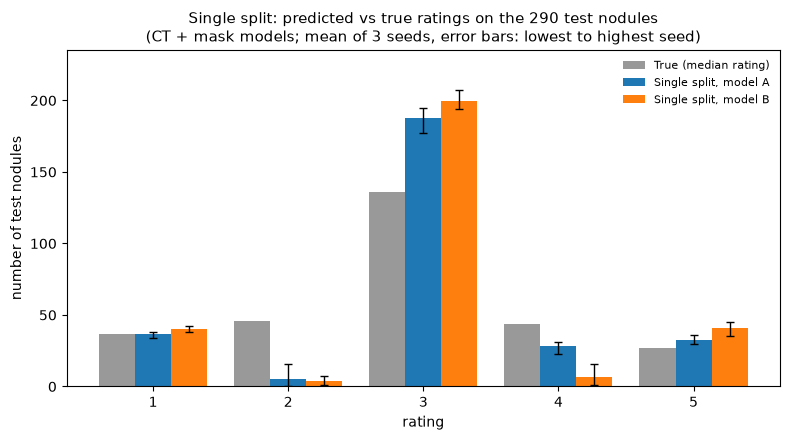

In [5]:
bars(["Single split, model A", "Single split, model B"], ["tab:blue", "tab:orange"],
     "Single split: predicted vs true ratings on the 290 test nodules\n"
     "(CT + mask models; mean of 3 seeds, error bars: lowest to highest seed)")

## Folds

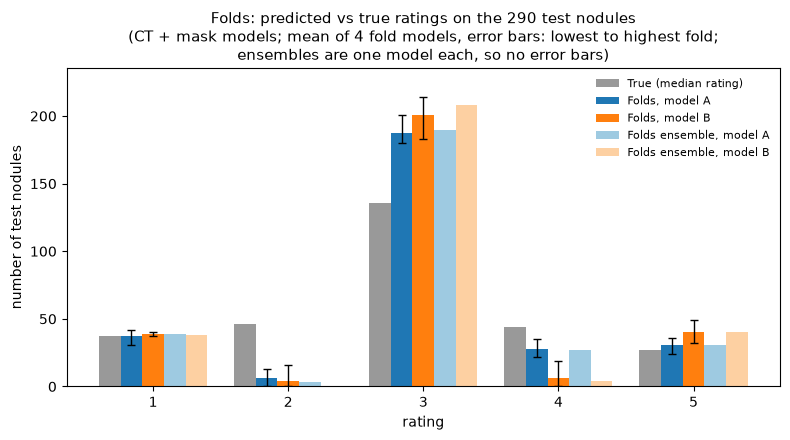

In [6]:
bars(["Folds, model A", "Folds, model B", "Folds ensemble, model A", "Folds ensemble, model B"],
     ["tab:blue", "tab:orange", "#9ecae1", "#fdd0a2"],
     "Folds: predicted vs true ratings on the 290 test nodules\n"
     "(CT + mask models; mean of 4 fold models, error bars: lowest to highest fold;\n"
     "ensembles are one model each, so no error bars)")